In [2]:
# Cell 1: Load Dataset and Display First 15 Rows

import pandas as pd

# Load the healthcare dataset
df = pd.read_csv("/content/1776250375-P2-Healthcare Analytics for Doctor Visits.csv")

# Display the first 15 rows
df.head(15)

,Unnamed: 0,visits,gender,age,income,illness,reduced,health,private,freepoor,freerepat,nchronic,lchronic
0,1,1,female,0.19,0.55,1,4,1,yes,no,no,no,no
1,2,1,female,0.19,0.45,1,2,1,yes,no,no,no,no
2,3,1,male,0.19,0.90,3,0,0,no,no,no,no,no
3,4,1,male,0.19,0.15,1,0,0,no,no,no,no,no
4,5,1,male,0.19,0.45,2,5,1,no,no,no,yes,no
5,6,1,female,0.19,0.35,5,1,9,no,no,no,yes,no
6,7,1,female,0.19,0.55,4,0,2,no,no,no,no,no
7,8,1,female,0.19,0.15,3,0,6,no,no,no,no,no
8,9,1,female,0.19,0.65,2,0,5,yes,no,no,no,no
9,10,1,male,0.19,0.15,1,0,0,yes,no,no,no,no


In [3]:
# Cell 2: Display Complete Information About Dataset Columns

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5190 entries, 0 to 5189
Data columns (total 13 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  5190 non-null   int64  
 1   visits      5190 non-null   int64  
 2   gender      5190 non-null   object 
 3   age         5190 non-null   float64
 4   income      5190 non-null   float64
 5   illness     5190 non-null   int64  
 6   reduced     5190 non-null   int64  
 7   health      5190 non-null   int64  
 8   private     5190 non-null   object 
 9   freepoor    5190 non-null   object 
 10  freerepat   5190 non-null   object 
 11  nchronic    5190 non-null   object 
 12  lchronic    5190 non-null   object 
dtypes: float64(2), int64(5), object(6)
memory usage: 527.2+ KB


In [4]:
# Cell 3: Count of People Based on Number of Illnesses

illness_count = df["illness"].value_counts().sort_index()

print("Total number of people based on their count of illness:")
print(illness_count)

Total number of people based on their count of illness:
illness
0    1554
1    1638
2     946
3     542
4     274
5     236
Name: count, dtype: int64


Maximum Income : 1.5
Minimum Income : 0.0
Medium Income  : 0.583159922928709


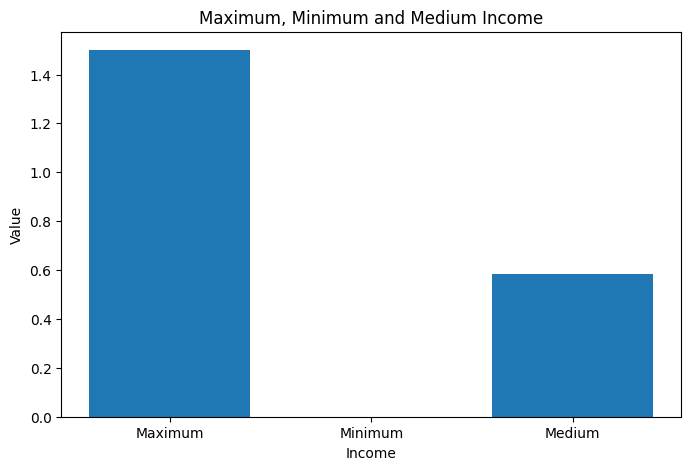

In [6]:
# Cell 4: Visualize and Analyze Maximum, Minimum and Medium Income

import matplotlib.pyplot as plt

# Calculate maximum, minimum and medium income
max_income = df["income"].max()
min_income = df["income"].min()
medium_income = df["income"].mean()

# Display the results
print("Maximum Income :", max_income)
print("Minimum Income :", min_income)
print("Medium Income  :", medium_income)

# Visualize the results
income_values = {
    "Maximum": max_income,
    "Minimum": min_income,
    "Medium": medium_income
}

plt.figure(figsize=(8, 5))
plt.bar(income_values.keys(), income_values.values())
plt.title("Maximum, Minimum and Medium Income")
plt.xlabel("Income")
plt.ylabel("Value")
plt.show()

In [7]:
# Cell 5: Number of Days of Reduced Activity by Gender Due to Illness

reduced_activity = df.groupby("gender")["reduced"].sum()

print("Number of days of reduced activity:")
print(reduced_activity)

Number of days of reduced activity:
gender
female    2636
male      1837
Name: reduced, dtype: int64


Missing values in each column:
Unnamed: 0    0
visits        0
gender        0
age           0
income        0
illness       0
reduced       0
health        0
private       0
freepoor      0
freerepat     0
nchronic      0
lchronic      0
dtype: int64


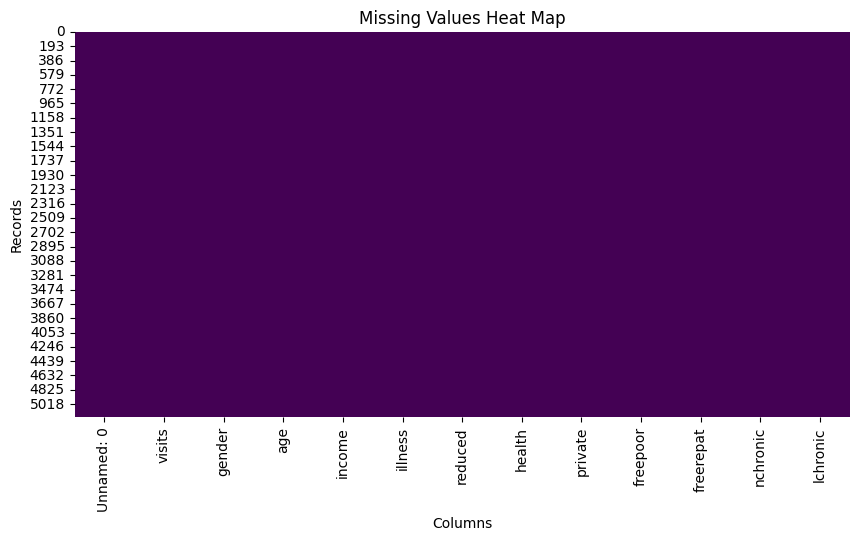

In [9]:
# Cell 6: Visualize Missing Values Using a Heat Map

import seaborn as sns
import matplotlib.pyplot as plt

# Check for missing values
print("Missing values in each column:")
print(df.isnull().sum())

# Create heat map
plt.figure(figsize=(10, 5))
sns.heatmap(df.isnull(), cbar=False, cmap="viridis")

plt.title("Missing Values Heat Map")
plt.xlabel("Columns")
plt.ylabel("Records")
plt.show()

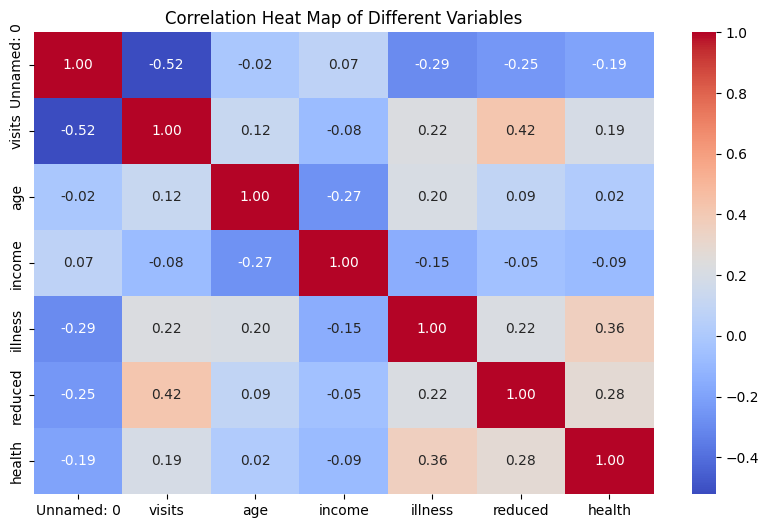

In [12]:
# Cell 8: Visualize Correlation Between Variables

import seaborn as sns
import matplotlib.pyplot as plt

# Calculate correlation matrix
correlation = df.corr(numeric_only=True)

# Create correlation heat map
plt.figure(figsize=(10, 6))
sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")

plt.title("Correlation Heat Map of Different Variables")
plt.show()

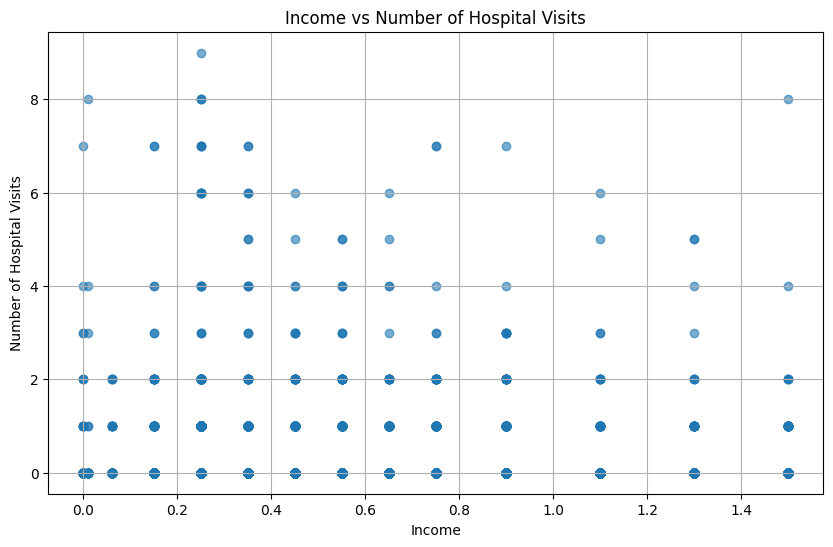

In [14]:
# Cell 9: Analyze How Income Affects the Number of Hospital Visits

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.scatter(df["income"], df["visits"], alpha=0.6)

plt.title("Income vs Number of Hospital Visits")
plt.xlabel("Income")
plt.ylabel("Number of Hospital Visits")
plt.grid(True)

plt.show()

Number of males and females affected by illness:
gender
female    2023
male      1613
Name: count, dtype: int64


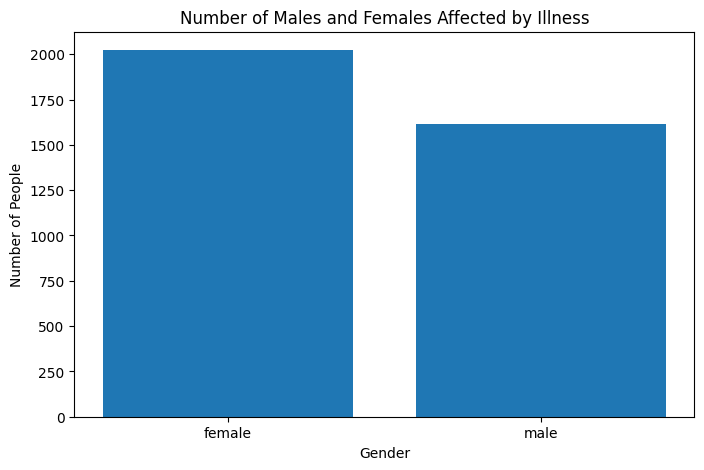

In [15]:
# Cell 10: Count and Visualize Number of Males and Females Affected by Illness

# Count males and females affected by illness
gender_illness = df[df["illness"] > 0]["gender"].value_counts()

print("Number of males and females affected by illness:")
print(gender_illness)

# Visualize the results
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.bar(gender_illness.index, gender_illness.values)

plt.title("Number of Males and Females Affected by Illness")
plt.xlabel("Gender")
plt.ylabel("Number of People")
plt.show()

Government health insurance due to low income: 4.28 %
Government health insurance due to old age: 21.02 %
Private health insurance: 44.28 %


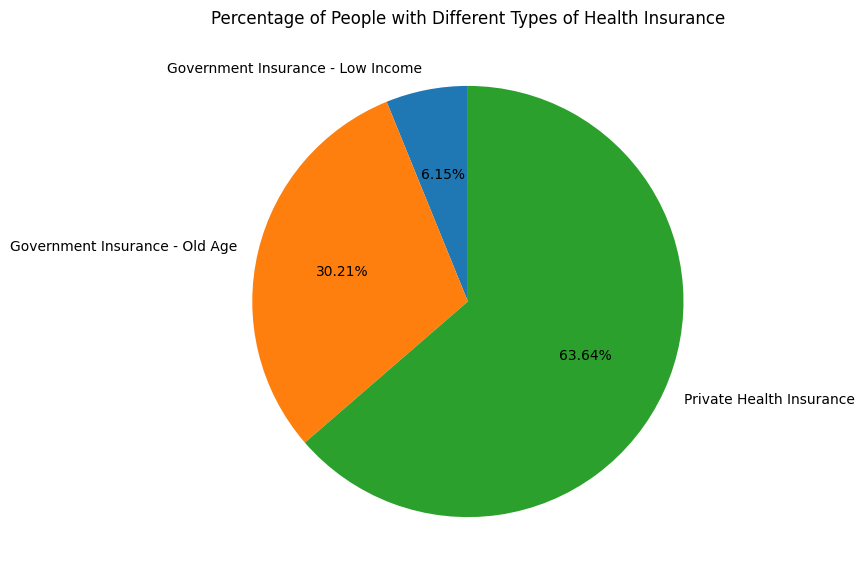

In [17]:
# Cell 11: Visualize Health Insurance Percentages Using Pie Chart

import matplotlib.pyplot as plt

# Calculate percentages
low_income = (df["freepoor"] == "yes").sum() / len(df) * 100
old_age = (df["freerepat"] == "yes").sum() / len(df) * 100
private = (df["private"] == "yes").sum() / len(df) * 100

# Display percentages
print("Government health insurance due to low income:", round(low_income, 2), "%")
print("Government health insurance due to old age:", round(old_age, 2), "%")
print("Private health insurance:", round(private, 2), "%")

# Pie chart
labels = [
    "Government Insurance - Low Income",
    "Government Insurance - Old Age",
    "Private Health Insurance"
]

values = [low_income, old_age, private]

plt.figure(figsize=(9, 7))
plt.pie(
    values,
    labels=labels,
    autopct="%1.2f%%",
    startangle=90
)

plt.title("Percentage of People with Different Types of Health Insurance")
plt.show()

Reduced days of activity due to illness based on gender:
gender
female    2636
male      1837
Name: reduced, dtype: int64


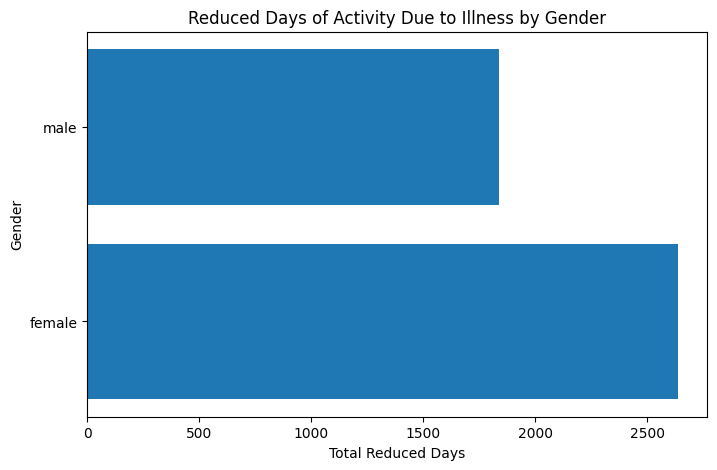

In [18]:
# Cell 12: Reduced Days of Activity Due to Illness Based on Gender

import matplotlib.pyplot as plt

# Calculate total reduced activity days by gender
reduced_days_gender = df.groupby("gender")["reduced"].sum()

# Display the results
print("Reduced days of activity due to illness based on gender:")
print(reduced_days_gender)

# Horizontal bar chart
plt.figure(figsize=(8, 5))
plt.barh(reduced_days_gender.index, reduced_days_gender.values)

plt.title("Reduced Days of Activity Due to Illness by Gender")
plt.xlabel("Total Reduced Days")
plt.ylabel("Gender")

plt.show()